<h1>Neural Network 1</h1>

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch 
import torch.nn as nn 
import torch.optim as optim


In [2]:
df=pd.read_csv("bonus.csv")

In [3]:
df.shape

(1000, 5)

In [4]:
df.head(5)

,employee_id,performance,years_of_experience,projects_completed,bonus
0,EMP_001,7,1,3,116
1,EMP_002,4,8,10,136
2,EMP_003,8,4,5,150
3,EMP_004,5,4,7,118
4,EMP_005,7,5,6,146


In [5]:
df.columns

Index(['employee_id', 'performance', 'years_of_experience',
       'projects_completed', 'bonus'],
      dtype='str')

In [6]:
X_train, X_test,y_train, y_test=train_test_split(df[['performance', 'years_of_experience',
       'projects_completed']].values, df[['bonus']].values, test_size=0.2, random_state=42)

In [7]:
torch.manual_seed(0)

#Tensors Conversion
X_train_tensor=torch.tensor(X_train,dtype=torch.float32)
X_test_tensor=torch.tensor(X_test,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test,dtype=torch.float32)

#### Training NN


In [8]:
class bonusPredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.network=nn.Sequential(
            nn.Linear(3,1)
        )
    
    def forward(self,x):
        return self.network(x)

In [9]:
model=bonusPredictor()
critierion=nn.MSELoss()
optimizer=optim.SGD(model.parameters(),lr=0.0052)

In [10]:
epochs=5000
for epoch in range(epochs):
    # 1. Forward Pass
    prediction=model(X_train_tensor)
    loss=critierion(prediction,y_train_tensor)

    # 2. Backward Pass
    optimizer.zero_grad()
    loss.backward()

    # 3. Update Weights
    optimizer.step()

    if (epoch+1)%100 ==0:
        print(f"epoch: {epoch}, loss: {loss.item():.2f}")

epoch: 99, loss: 22.05
epoch: 199, loss: 18.91
epoch: 299, loss: 16.42
epoch: 399, loss: 14.32
epoch: 499, loss: 12.52
epoch: 599, loss: 10.95
epoch: 699, loss: 9.58
epoch: 799, loss: 8.38
epoch: 899, loss: 7.34
epoch: 999, loss: 6.42
epoch: 1099, loss: 5.62
epoch: 1199, loss: 4.92
epoch: 1299, loss: 4.30
epoch: 1399, loss: 3.77
epoch: 1499, loss: 3.30
epoch: 1599, loss: 2.88
epoch: 1699, loss: 2.52
epoch: 1799, loss: 2.21
epoch: 1899, loss: 1.93
epoch: 1999, loss: 1.69
epoch: 2099, loss: 1.48
epoch: 2199, loss: 1.30
epoch: 2299, loss: 1.13
epoch: 2399, loss: 0.99
epoch: 2499, loss: 0.87
epoch: 2599, loss: 0.76
epoch: 2699, loss: 0.67
epoch: 2799, loss: 0.58
epoch: 2899, loss: 0.51
epoch: 2999, loss: 0.45
epoch: 3099, loss: 0.39
epoch: 3199, loss: 0.34
epoch: 3299, loss: 0.30
epoch: 3399, loss: 0.26
epoch: 3499, loss: 0.23
epoch: 3599, loss: 0.20
epoch: 3699, loss: 0.18
epoch: 3799, loss: 0.15
epoch: 3899, loss: 0.13
epoch: 3999, loss: 0.12
epoch: 4099, loss: 0.10
epoch: 4199, loss: 0.

#### Evalution

In [11]:
model.eval()

bonusPredictor(
  (network): Sequential(
    (0): Linear(in_features=3, out_features=1, bias=True)
  )
)

In [12]:
with torch.no_grad():
    test_predictions=model(X_test_tensor)
    test_loss=critierion(test_predictions,y_test_tensor)

print(f"Test Loss: { test_loss.item():.2f}")

Test Loss: 0.03


Getting Parameters

In [13]:
for name,value in model.named_parameters():
    print(f"Name: {name}, value {value}")

Name: network.0.weight, value Parameter containing:
tensor([[12.0293,  5.8657,  2.1601]], requires_grad=True)
Name: network.0.bias, value Parameter containing:
tensor([19.3380], requires_grad=True)


# Neural Network 2


In [ ]:
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [ ]:
training_data=datasets.FashionMNIST(
    download=True,
    root="Data",
    train=True,
    transform=ToTensor()
)

In [ ]:
test_data=datasets.FashionMNIST(
    download=True,
    root="Data",
    train=False,
    transform=ToTensor()
)

In [ ]:
image,label=training_data[0]

In [ ]:
label

9

In [ ]:
label_dict = {
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}


In [ ]:
label_dict[label]

'Ankle boot'

In [ ]:
image.squeeze().shape

torch.Size([28, 28])

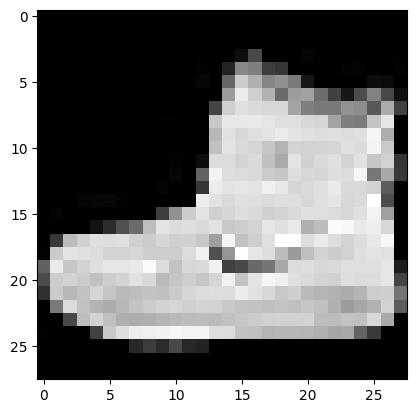

In [ ]:
plt.imshow(image.squeeze(),cmap="gray")

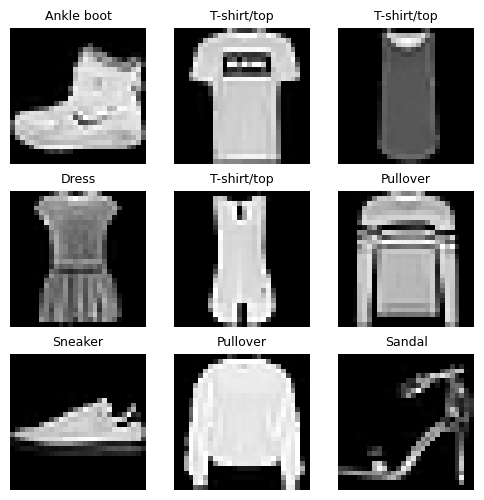

In [ ]:
labels_map = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}
fig, axes = plt.subplots(3, 3, figsize=(6, 6))

for i, ax in enumerate(axes.flat):
    image, label =training_data[i]
    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(labels_map[label], fontsize=9)
    ax.axis("off")

plt.show()


Data Loader

In [ ]:
from torch.utils.data import DataLoader
train_data_loader= DataLoader(training_data, batch_size=64, shuffle=True)
test_data_loader= DataLoader(test_data, batch_size=64,shuffle=True)
data_iter=iter(train_data_loader)
image,labels=next(data_iter)

# Ex3

In [ ]:
train_data = datasets.MNIST(
    root="Data",
    train=True,
    download=True,
    transform=ToTensor()
)

In [ ]:
test_data = datasets.MNIST(
    root="Data",
    train=False,
    download=True,
    transform=ToTensor()
)

In [ ]:
image, label = train_data[0]

print(image.shape)   # torch.Size([1, 28, 28])
print(label)         # 0–9


torch.Size([1, 28, 28])
5


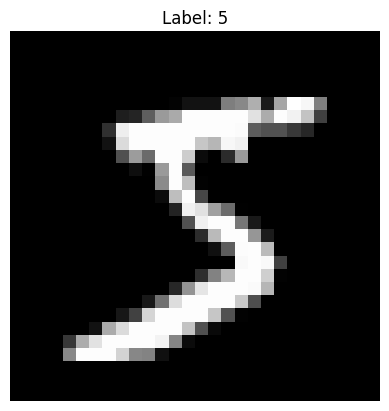

In [ ]:
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()


In [ ]:
train_data_loader= DataLoader(training_data, batch_size=64, shuffle=True)
test_data_loader= DataLoader(test_data, batch_size=64,shuffle=True)
data_iter=iter(train_data_loader)